# 01 · Amazon Beauty: Data Exploration

Milestone 1 of the hands-on track. Goals:
- understand the shape of the interaction data (users, items, sequence lengths, popularity skew)
- check the item metadata we'll turn into **semantic embeddings** and **Semantic IDs** in milestones 2–4

Prepare the data first: `python scripts/prepare_data.py`

In [1]:
import os
os.chdir('..')  # run from repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from genrec.data.amazon import load_processed
from genrec.data.sequences import leave_one_out

sequences, items = load_processed('data/processed/beauty')

## Basic statistics
These should match the numbers reported in TIGER / SASRec for Beauty 5-core.

In [2]:
lengths = np.array([len(s) for s in sequences])
n_users, n_items, n_inter = len(sequences), len(items), lengths.sum()
pd.Series({
    'users': n_users,
    'items': n_items,
    'interactions': n_inter,
    'avg seq length': round(lengths.mean(), 2),
    'median seq length': np.median(lengths),
    'max seq length': lengths.max(),
    'density': f'{n_inter / (n_users * n_items):.5%}',
})

users                   22363
items                   12101
interactions           198502
avg seq length           8.88
median seq length         6.0
max seq length            204
density              0.07335%
dtype: object

## Sequence lengths
Most users have very short histories. With leave-one-out, a 5-item user trains on only 3 items, so models must generalize from little per-user signal. This is where item *content* (semantics) can help.

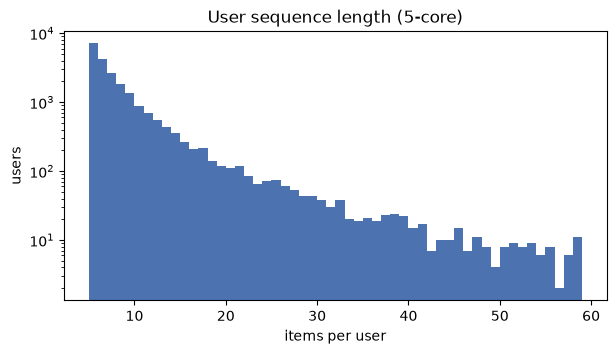

share of users with <= 7 items: 62.9%


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(lengths, bins=range(5, 60), color='#4C72B0')
ax.set(xlabel='items per user', ylabel='users', title='User sequence length (5-core)')
ax.set_yscale('log')
plt.show()
print('share of users with <= 7 items:', f'{(lengths <= 7).mean():.1%}')

## Item popularity: the long tail
Popularity is skewed but not extreme, which is why the popularity baseline is weak here.

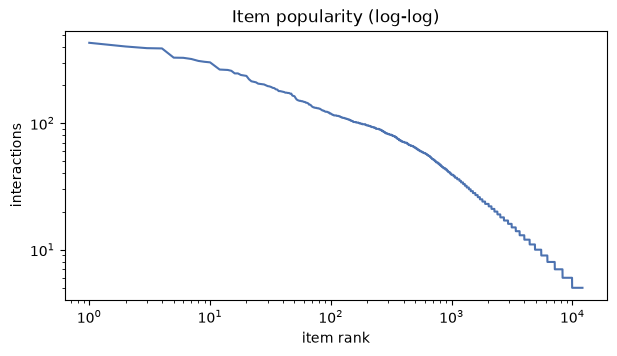

top 1% of items cover 10.5% of interactions
top 10% of items cover 42.8% of interactions


In [4]:
counts = pd.Series(np.concatenate(sequences)).value_counts()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(counts) + 1), counts.values, color='#4C72B0')
ax.set(xscale='log', yscale='log', xlabel='item rank', ylabel='interactions', title='Item popularity (log-log)')
plt.show()
top = counts.cumsum() / counts.sum()
print('top 1% of items cover', f'{top.iloc[len(counts) // 100]:.1%}', 'of interactions')
print('top 10% of items cover', f'{top.iloc[len(counts) // 10]:.1%}', 'of interactions')

## Leave-one-out split
Last item = test target, second-to-last = validation target, the rest = training.

In [5]:
train, valid, test = leave_one_out(sequences)
print('example sequence:', sequences[0])
print('train:', train[0])
print('valid:', valid[0][0], '->', valid[1][0])
print('test: ', test[0][0], '->', test[1][0])
unseen = set(test[1]) - set(i for s in train for i in s)
print('test targets never seen in training:', len(unseen))

example sequence: [9450, 9840, 10077, 11156, 11753, 11864]
train: [9450, 9840, 10077, 11156]
valid: [9450, 9840, 10077, 11156] -> 11753
test:  [9450, 9840, 10077, 11156, 11753] -> 11864
test targets never seen in training: 33


## Item metadata: the semantic data
Coverage of each field, and the text we will embed in milestone 2.

In [6]:
coverage = pd.Series({
    col: (items[col].astype(str).str.len() > 0).mean() for col in ['title', 'brand', 'categories', 'price', 'description']
})
coverage.map('{:.1%}'.format).rename('non-empty')

title           99.9%
brand           82.7%
categories     100.0%
price           95.2%
description     92.2%
Name: non-empty, dtype: str

In [7]:
pd.set_option('display.max_colwidth', 200)
items[['asin', 'text']].sample(5, random_state=0)

,asin,text
item_idx,,
2471,B000W30RP8,"Title: Suave Naturals Gentle Cleansing Shampoo, Waterfall Mist, 12 oz. Brand: Suave. Categories: Beauty, Hair Care, Shampoos. Price: $5.95"
5202,B002R277E6,"Title: NYX Slim Lip Liner Pencil 824 Orange. Brand: NYX. Categories: Beauty, Makeup, Lips, Lip Liners. Price: $4.20"
8521,B005REYEXS,"Title: Hyaluronic Acid Serum - Organic &amp; Vegan - 100% Pure of a 1% solution 2oz. Categories: Beauty, Skin Care, Face, Oils & Serums. Price: $28.99"
9245,B0072F80DK,"Title: OGX Body Wash, Hydrating Argan Oil of Morocco, 13oz. Categories: Beauty, Bath & Body, Cleansers, Body Washes. Price: $13.20"
2917,B0013OMHTE,"Title: Neutrogena Ultra Sheer DryTouch Sunscreen, SPF 45, 3 Ounce. Brand: Neutrogena. Categories: Beauty, Skin Care, Sun, Skin Protection, Sports. Price: $3.00"


### Category structure
Categories are hierarchical, much like the coarse-to-fine levels a Semantic ID tries to learn.

In [8]:
level2 = items['categories'].str.split(' \\| ').str[0].str.split(', ').str[1]
level2.value_counts().head(10)

categories
Skin Care              3814
Hair Care              3262
Makeup                 2627
Tools & Accessories    1222
Bath & Body             684
Fragrance               492
Name: count, dtype: int64

In [9]:
words = items['text'].str.split().str.len()
print('text length (words): mean', round(words.mean(), 1), ' p95', int(words.quantile(0.95)))

text length (words): mean 23.6  p95 33


## Takeaways
- Sparse, short sequences make it hard to learn ID embeddings for tail items, so content-based semantics should help.
- Titles and categories are almost always present, and brand usually is: good inputs for a text encoder.
- The category hierarchy suggests what a good Semantic ID prefix should capture.

Baseline results are logged in `experiments/RESULTS.md`.